In [1]:
# 任务1：独热表示与分布式表示（SVD 降维）
import numpy as np
import pandas as pd
from itertools import combinations

demo_words = ["猫", "狗", "鸟", "飞机"]
demo_ids = {w: i for i, w in enumerate(demo_words)}
demo_onehot = np.eye(len(demo_words), dtype=float)
print(pd.DataFrame(demo_onehot, index=demo_words, columns=demo_words))


      猫    狗    鸟   飞机
猫   1.0  0.0  0.0  0.0
狗   0.0  1.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0
飞机  0.0  0.0  0.0  1.0


In [2]:
demo_sentences = [
    "可爱 猫 宠物", "可爱 狗 宠物",
    "家中 猫 陪伴", "家中 狗 陪伴",
    "猫 吃 鱼", "狗 吃 肉",
    "鸟 天空 飞翔", "鸟 树林 飞翔",
    "飞机 天空 飞行", "飞机 机场 飞行",
    "鸟 空中 移动", "飞机 空中 移动",
]
demo_tokens = [s.split() for s in demo_sentences]
demo_contexts = sorted({w for sent in demo_tokens for w in sent} - set(demo_words))
demo_context_ids = {w: i for i, w in enumerate(demo_contexts)}
demo_counts = np.zeros((len(demo_words), len(demo_contexts)), dtype=float)
for sent in demo_tokens:
    for pos, word in enumerate(sent):
        if word not in demo_ids:
            continue
        for j in range(max(0, pos - 2), min(len(sent), pos + 3)):
            if j != pos and sent[j] in demo_context_ids:
                demo_counts[demo_ids[word], demo_context_ids[sent[j]]] += 1
print(pd.DataFrame(demo_counts, index=demo_words, columns=demo_contexts).to_string())


     可爱    吃   天空   宠物   家中   机场   树林   移动   空中    肉   陪伴   飞翔   飞行    鱼
猫   1.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  0.0  1.0  0.0  0.0  1.0
狗   1.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  0.0  1.0  1.0  0.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0  0.0  0.0  1.0  1.0  1.0  0.0  0.0  2.0  0.0  0.0
飞机  0.0  0.0  1.0  0.0  0.0  1.0  0.0  1.0  1.0  0.0  0.0  0.0  2.0  0.0


In [3]:
# 行归一化后截断 SVD，取前3维作为词向量
demo_x = demo_counts / np.maximum(np.linalg.norm(demo_counts, axis=1, keepdims=True), 1e-12)
demo_u, demo_s, demo_vh = np.linalg.svd(demo_x, full_matrices=False)
demo_dense = demo_u[:, :3] * demo_s[:3]
assert demo_dense.shape == (4, 3)
assert np.all(np.linalg.norm(demo_dense, axis=1) > 0)
print(pd.DataFrame(demo_dense, index=demo_words, columns=["维度1", "维度2", "维度3"]).round(4))
print("独热表示形状：", demo_onehot.shape)
print("分布式表示形状：", demo_dense.shape)


       维度1     维度2    维度3
猫  -0.9574  0.0000  0.000
狗  -0.9574  0.0000  0.000
鸟   0.0000 -0.8292 -0.559
飞机  0.0000 -0.8292  0.559
独热表示形状： (4, 4)
分布式表示形状： (4, 3)


In [4]:
# 相同词对、相同指标生成两种表示的对照表
def compare_representations(words, onehot_vectors, dense_vectors):
    records = []
    for i, j in combinations(range(len(words)), 2):
        row = {"词对": f"{words[i]}—{words[j]}"}
        for label, vectors in [("独热", onehot_vectors), ("分布式", dense_vectors)]:
            a, b = vectors[i], vectors[j]
            denominator = np.linalg.norm(a) * np.linalg.norm(b)
            row[f"{label}_欧氏距离"] = float(np.linalg.norm(a - b))
            row[f"{label}_余弦相似度"] = float(a @ b / denominator) if denominator > 0 else np.nan
        records.append(row)
    return pd.DataFrame(records)

demo_comparison = compare_representations(demo_words, demo_onehot, demo_dense)
print(demo_comparison.round(4).to_string(index=False))
assert np.allclose(demo_comparison["独热_欧氏距离"], np.sqrt(2))
assert np.allclose(demo_comparison["独热_余弦相似度"], 0)


  词对  独热_欧氏距离  独热_余弦相似度  分布式_欧氏距离  分布式_余弦相似度
 猫—狗   1.4142       0.0    0.0000      1.000
 猫—鸟   1.4142       0.0    1.3844      0.000
猫—飞机   1.4142       0.0    1.3844      0.000
 狗—鸟   1.4142       0.0    1.3844      0.000
狗—飞机   1.4142       0.0    1.3844      0.000
鸟—飞机   1.4142       0.0    1.1180      0.375


In [5]:
# 输出余弦相似度矩阵并保存结果
from pathlib import Path

def row_cosine_matrix(vectors):
    normalized = vectors / np.maximum(np.linalg.norm(vectors, axis=1, keepdims=True), 1e-12)
    return normalized @ normalized.T

print("独热表示的余弦相似度矩阵：")
print(pd.DataFrame(row_cosine_matrix(demo_onehot), index=demo_words, columns=demo_words).round(4))
print("分布式表示的余弦相似度矩阵：")
print(pd.DataFrame(row_cosine_matrix(demo_dense), index=demo_words, columns=demo_words).round(4))
Path("output").mkdir(exist_ok=True)
demo_comparison.to_csv("output/task1_comparison.csv", index=False, encoding="utf-8-sig")


独热表示的余弦相似度矩阵：
      猫    狗    鸟   飞机
猫   1.0  0.0  0.0  0.0
狗   0.0  1.0  0.0  0.0
鸟   0.0  0.0  1.0  0.0
飞机  0.0  0.0  0.0  1.0
分布式表示的余弦相似度矩阵：
      猫    狗      鸟     飞机
猫   1.0  1.0  0.000  0.000
狗   1.0  1.0  0.000  0.000
鸟   0.0  0.0  1.000  0.375
飞机  0.0  0.0  0.375  1.000


In [6]:
# 任务2：构造上下文窗口与训练样本
sentences = [
    "猫 喜欢 吃 鱼",
    "狗 喜欢 吃 肉",
    "猫 和 狗 都 是 宠物",
    "小猫 是 可爱 的 宠物",
    "小狗 是 忠诚 的 宠物",
    "鱼 生活 在 水中",
    "鸟 喜欢 在 天空 飞翔",
    "飞机 在 天空 飞行",
]

corpus = " ".join(sentences).split()
print("语料词数：", len(corpus))
print("前20个词：", corpus[:20])


语料词数： 37
前20个词： ['猫', '喜欢', '吃', '鱼', '狗', '喜欢', '吃', '肉', '猫', '和', '狗', '都', '是', '宠物', '小猫', '是', '可爱', '的', '宠物', '小狗']


In [7]:
# 建立词表
from collections import Counter

word_counts = Counter(corpus)
vocab = sorted(word_counts, key=word_counts.get, reverse=True)
word_to_id = {word: i for i, word in enumerate(vocab)}
id_to_word = {i: word for word, i in word_to_id.items()}

print("词表大小：", len(vocab))
print("词表：", vocab)


词表大小： 23
词表： ['喜欢', '是', '宠物', '在', '猫', '吃', '鱼', '狗', '的', '天空', '肉', '和', '都', '小猫', '可爱', '小狗', '忠诚', '生活', '水中', '鸟', '飞翔', '飞机', '飞行']


In [8]:
# 滑动窗口构造 Skip-gram 训练样本（中心词, 上下文词）
def make_skipgram_pairs(tokens, word_to_id, window_size=1):
    pairs = []
    for center_pos, center_word in enumerate(tokens):
        center_id = word_to_id[center_word]
        left = max(0, center_pos - window_size)
        right = min(len(tokens), center_pos + window_size + 1)

        for context_pos in range(left, right):
            if context_pos == center_pos:
                continue
            context_word = tokens[context_pos]
            pairs.append((center_id, word_to_id[context_word]))
    return pairs

sentence_tokens = [sentence.split() for sentence in sentences]
pairs = [pair for tokens in sentence_tokens
         for pair in make_skipgram_pairs(tokens, word_to_id, window_size=1)]

print("训练样本数：", len(pairs))
for center_id, context_id in pairs[:10]:
    print(id_to_word[center_id], "→", id_to_word[context_id])


训练样本数： 58
猫 → 喜欢
喜欢 → 猫
喜欢 → 吃
吃 → 喜欢
吃 → 鱼
鱼 → 吃
狗 → 喜欢
喜欢 → 狗
喜欢 → 吃
吃 → 喜欢


In [9]:
# 比较不同窗口大小
for window_size in [1, 2, 3]:
    current_pairs = [pair for tokens in sentence_tokens
                     for pair in make_skipgram_pairs(tokens, word_to_id, window_size)]
    print(f"窗口大小={window_size}, 样本数={len(current_pairs)}")


窗口大小=1, 样本数=58


窗口大小=2, 样本数=100
窗口大小=3, 样本数=126


In [10]:
# 任务3：实现并训练 Skip-gram（PyTorch）
import torch
import torch.nn as nn
import torch.optim as optim

torch.manual_seed(42)


In [11]:
# Skip-gram 模型：Embedding 查表 + Linear 输出
class SkipGram(nn.Module):
    def __init__(self, vocab_size, embedding_dim=10):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.output = nn.Linear(embedding_dim, vocab_size)

    def forward(self, center_words):
        vectors = self.embedding(center_words)
        logits = self.output(vectors)
        return logits


In [12]:
# 训练数据张量化
centers = torch.tensor([p[0] for p in pairs], dtype=torch.long)
contexts = torch.tensor([p[1] for p in pairs], dtype=torch.long)

print("中心词张量形状：", centers.shape)
print("上下文词张量形状：", contexts.shape)


中心词张量形状： torch.Size([58])
上下文词张量形状： torch.Size([58])


In [13]:
# 训练 1000 轮，记录损失
embedding_dim = 10
model = SkipGram(len(vocab), embedding_dim=embedding_dim)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.03)

loss_history = []

for epoch in range(1000):
    optimizer.zero_grad()
    logits = model(centers)
    loss = criterion(logits, contexts)
    loss.backward()
    optimizer.step()

    loss_history.append(loss.item())

    if (epoch + 1) % 200 == 0:
        print(f"epoch={epoch + 1}, loss={loss.item():.4f}")


epoch=200, loss=0.9814


epoch=400, loss=0.9808


epoch=600, loss=0.9806


epoch=800, loss=0.9805


epoch=1000, loss=0.9805


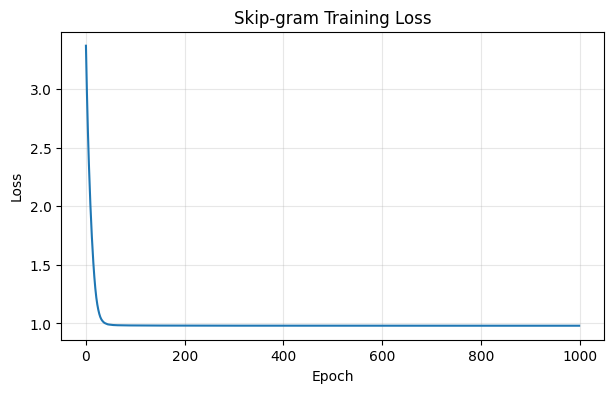

In [14]:
# 绘制损失曲线
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 4))
plt.plot(loss_history)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Skip-gram Training Loss")
plt.grid(alpha=0.3)
plt.show()


In [15]:
# 任务4：词向量相似度分析
embeddings = model.embedding.weight.detach()
print("词向量矩阵形状：", embeddings.shape)


词向量矩阵形状： torch.Size([23, 10])


In [16]:
# 余弦相似度
import torch.nn.functional as F

def cosine_similarity(word_a, word_b):
    vec_a = embeddings[word_to_id[word_a]].unsqueeze(0)
    vec_b = embeddings[word_to_id[word_b]].unsqueeze(0)
    return F.cosine_similarity(vec_a, vec_b).item()

for pair in [("猫", "狗"), ("天空", "飞机"), ("猫", "飞机"), ("鱼", "水中")]:
    print(pair, cosine_similarity(*pair))


('猫', '狗') 0.7484437823295593
('天空', '飞机') 0.5342141389846802
('猫', '飞机') 0.354570209980011
('鱼', '水中') -0.37214502692222595


In [17]:
# 查询最相似词
def most_similar(word, top_k=5):
    target_id = word_to_id[word]
    target = embeddings[target_id].unsqueeze(0)
    similarities = F.cosine_similarity(target, embeddings)

    result = []
    for idx in torch.argsort(similarities, descending=True):
        idx = idx.item()
        if idx == target_id:
            continue
        result.append((id_to_word[idx], float(similarities[idx])))
        if len(result) >= top_k:
            break
    return result

for word in ["猫", "狗", "天空", "宠物"]:
    print(f"{word} 的相似词：", most_similar(word))


猫 的相似词： [('狗', 0.7484437823295593), ('鸟', 0.4791223406791687), ('在', 0.44971176981925964), ('飞翔', 0.39766237139701843), ('飞行', 0.362668514251709)]
狗 的相似词： [('猫', 0.7484437823295593), ('鸟', 0.3281325697898865), ('忠诚', 0.21707698702812195), ('飞翔', 0.20640970766544342), ('在', 0.17947092652320862)]
天空 的相似词： [('水中', 0.6922759413719177), ('飞机', 0.5342141389846802), ('鸟', 0.3054409623146057), ('生活', 0.2645106315612793), ('喜欢', 0.14344635605812073)]
宠物 的相似词： [('可爱', 0.8576368689537048), ('忠诚', 0.7224279046058655), ('小猫', 0.5098384618759155), ('小狗', 0.4703502058982849), ('都', 0.23543407022953033)]


In [18]:
# 与任务1对比：训练所得向量 vs 独热表示
trained_compare_words = ["猫", "狗", "鸟", "飞机"]
trained_ids = [word_to_id[w] for w in trained_compare_words]
trained_vectors = embeddings[trained_ids].cpu().numpy()
trained_onehot = np.eye(len(vocab), dtype=float)[trained_ids]
trained_comparison = compare_representations(trained_compare_words, trained_onehot, trained_vectors)
print(trained_comparison.round(4).to_string(index=False))
trained_comparison.to_csv("output/task4_trained_comparison.csv", index=False, encoding="utf-8-sig")


  词对  独热_欧氏距离  独热_余弦相似度  分布式_欧氏距离  分布式_余弦相似度
 猫—狗   1.4142       0.0    4.2782     0.7484
 猫—鸟   1.4142       0.0    5.8127     0.4791
猫—飞机   1.4142       0.0    6.3371     0.3546
 狗—鸟   1.4142       0.0    5.9453     0.3281
狗—飞机   1.4142       0.0    6.4825     0.1668
鸟—飞机   1.4142       0.0    6.6240    -0.0466


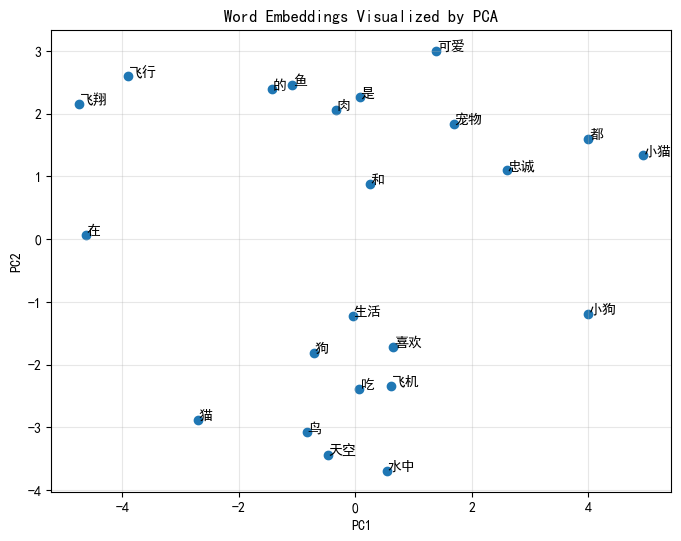

In [19]:
# 任务5（选做）：PCA 二维可视化
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

from sklearn.decomposition import PCA

vectors = embeddings.numpy()
pca = PCA(n_components=2)
points = pca.fit_transform(vectors)

plt.figure(figsize=(8, 6))
plt.scatter(points[:, 0], points[:, 1])

for i, word in enumerate(vocab):
    plt.text(points[i, 0] + 0.01, points[i, 1] + 0.01, word)

plt.title("Word Embeddings Visualized by PCA")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.grid(alpha=0.3)
plt.show()
